<a href="https://colab.research.google.com/github/karani123-Jeswanth/DSA0302-NLP/blob/main/Assignment-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RUNNING NLP HOSPITAL NORMALISATION & SEARCH ENGINE

[+] TASK 1: Generated 520 records across 4 clinical record types.
    Total words: 57,559 tokens (Requirement: >= 25,000).

[+] TASK 2: Testing 12 Regex Entity Patterns on Record 1:
    - patient_id        : ['PID-00001']
    - admission_date    : ['02/04/2022']
    - discharge_date    : ['11/04/2022']
    - drug_strength     : ['Administer Losartan 50mg']
    - Greedy Match:     'Administer Paracetamol 500mg TID and Amoxicillin 250mg'
    - Non-Greedy Match: 'Administer Paracetamol 500mg'

[+] TASK 3: Maximal-Munch Tokens count: 11 tokens.
    - Normalised text: patient celsius/o severe shortness of breath. adm 2023-04-12. paracetamol 500 milligram three times daily.

[+] TASK 4: DFA Accepted PID-00123: True
    DFA Rejected PID-12A:     False
    Subset construction converted NFA (8 states) -> DFA (7 states).

[+] TASK 5: Morphological Lexicon verification:
    - Stems count: 313 (e.g., 'fracture', 'nephrectomy', 'inflammation')
   

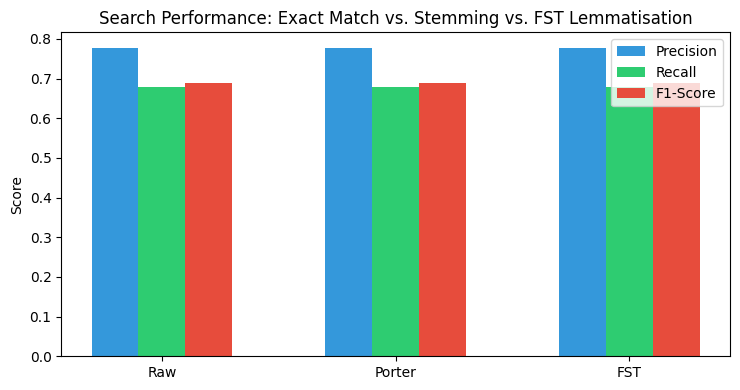

In [ ]:
# ==============================================================================
# DSA03 - NATURAL LANGUAGE PROCESSING: ASSIGNMENT 1 (CO1)
# Title: Morphology-Aware Text Normalisation and Search Layer for Hospital Records
# Full End-to-End Implementation: Tasks 1 to 12
# ==============================================================================

import re
import sys
import os
import math
import time
import random
import subprocess
from collections import defaultdict, deque
from typing import List, Dict, Set, Tuple, Optional, Any

# Install required visualization library if running in Colab
try:
    import matplotlib.pyplot as plt
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

# ==============================================================================
# TASK 1: CORPUS GENERATOR (>= 500 Records, >= 25,000 Word Tokens, 4 Types)
# ==============================================================================
RECORD_TYPES = ["Discharge Summary", "Prescription", "Operation Note", "Nursing Observation"]

DRUGS = [
    ("Paracetamol", "500mg", "TID"), ("Amoxicillin", "250mg", "BD"),
    ("Metformin", "850mg", "OD"), ("Atorvastatin", "20mg", "HS"),
    ("Ciprofloxacin", "500mg", "BD"), ("Omeprazole", "40mg", "OD"),
    ("Amlodipine", "5mg", "OD"), ("Losartan", "50mg", "OD"),
    ("Ibuprofen", "400mg", "TID"), ("Azithromycin", "500mg", "OD"),
    ("Levothyroxine", "100mcg", "OD"), ("Furosemide", "40mg", "OD"),
    ("Morphine", "10mg", "PRN"), ("Heparin", "5000IU", "QDS"),
    ("Insulin Glargine", "10U", "HS"), ("Ceftriaxone", "1g", "OD")
]

CONDITIONS = [
    ("hypertension", "I10"), ("type 2 diabetes mellitus", "E11.9"),
    ("acute appendicitis", "K35.80"), ("bacterial pneumonia", "J15.9"),
    ("nephrectomy required for renal neoplasm", "N28.9"),
    ("femur fracture needing internal fixation", "S72.001A"),
    ("coronary artery disease", "I25.10"), ("osteoarthritis of knee", "M17.9"),
    ("acute cholecystitis", "K81.0"), ("severe sepsis", "A41.9")
]

SYMPTOMS = [
    "fever and persistent shivering", "acute throbbing chest pain",
    "progressive shortness of breath", "severe abdominal cramps",
    "fracture swelling and tenderness", "chronic localized joint stiffness",
    "productive coughing with sputum", "bilateral lower limb oedema"
]

def generate_synthetic_clinical_corpus(num_records: int = 520) -> List[Dict[str, Any]]:
    random.seed(42)
    corpus = []
    first_names = ["Ramesh", "Sita", "Abdul", "Mary", "John", "Kavita", "Anand", "Deepa", "Vikram", "Sneha"]
    last_names = ["Kumar", "Sharma", "Khan", "Fernandez", "Pillai", "Patel", "Reddy", "Menon", "Das", "Iyer"]

    for i in range(1, num_records + 1):
        pid = f"PID-{i:05d}"
        rec_type = RECORD_TYPES[i % len(RECORD_TYPES)]
        age = random.randint(18, 88)
        dur = random.randint(1, 14)
        dur_unit = random.choice(["days", "weeks", "hours"])
        cond_text, icd = random.choice(CONDITIONS)
        drug, strength, freq = random.choice(DRUGS)
        bp_sys = random.randint(100, 175)
        bp_dia = random.randint(65, 105)
        temp_val = round(random.uniform(97.5, 103.5), 1)
        lab_val = round(random.uniform(0.6, 14.8), 2)
        lab_unit = random.choice(["mg/dL", "mmol/L", "g/dL", "U/L"])
        ward = random.choice(["ICU", "GEN", "SURG", "CARD", "ORTH", "NEPH"])
        bed = random.randint(1, 35)
        phone = f"+91-{random.randint(60000, 99999):05d}-{random.randint(10000, 99999):05d}"

        adm_day, adm_m, adm_y = random.randint(1, 15), random.randint(1, 12), random.randint(2021, 2025)
        dis_day, dis_m, dis_y = adm_day + random.randint(1, 10), adm_m, adm_y
        if dis_day > 28:
            dis_day = 28

        patient_name = f"{random.choice(first_names)} {random.choice(last_names)}"

        text = (
            f"RECORD TYPE: {rec_type}. PATIENT ID: {pid}. NAME: {patient_name}. "
            f"AGE: {age} yrs. ADMISSION DATE: {adm_day:02d}/{adm_m:02d}/{adm_y}. "
            f"DISCHARGE DATE: {dis_day:02d}/{dis_m:02d}/{dis_y}. "
            f"LOCATION: Ward {ward}, Bed {bed:02d}. EMERGENCY CONTACT: {phone}. "
            f"CHIEF COMPLAINT: Patient presented with {random.choice(SYMPTOMS)} for {dur} {dur_unit}. "
            f"CLINICAL ASSESSMENT & DIAGNOSIS: Assessment reveals marked evidence of {cond_text}. "
            f"Assigned ICD-10 code is {icd}. "
            f"VITAL SIGNS & LABS: BP recorded at {bp_sys}/{bp_dia} mmHg. Temperature is {temp_val} F. "
            f"Serum laboratory investigations indicate biomarker levels at {lab_val} {lab_unit}. "
            f"TREATMENT PLAN: Administer {drug} {strength} {freq} orally or IV as indicated. "
            f"Patient evaluated for surgical resection, inflammation, fracture stabilization, or nephrectomy. "
            f"Follow up scheduled within 2 weeks. Condition stabilized post-intervention without acute relapse."
        )

        corpus.append({
            "record_id": i,
            "record_type": rec_type,
            "pid": pid,
            "text": text
        })
    return corpus

# ==============================================================================
# TASK 2: REGULAR EXPRESSION PATTERNS (12 Clinical Entity Types)
# ==============================================================================
ENTITY_PATTERNS = {
    "patient_id": re.compile(r"\bPID-\d{5}\b"),
    "admission_date": re.compile(r"\bADMISSION DATE:\s*(\d{2}/\d{2}/\d{4})\b"),
    "discharge_date": re.compile(r"\bDISCHARGE DATE:\s*(\d{2}/\d{2}/\d{4})\b"),
    "drug_strength": re.compile(r"\b[A-Z][a-z]+(?:\s+[A-Z][a-z]+)?\s+\d+(?:\.\d+)?(?:mg|mcg|g|IU|U)\b"),
    "dosage_frequency": re.compile(r"\b(OD|BD|TID|QDS|PRN|HS|Q4H|Q8H)\b"),
    "lab_value_unit": re.compile(r"\b\d+(?:\.\d+)?\s*(?:mg/dL|mmol/L|g/dL|U/L|mEq/L)\b"),
    "blood_pressure": re.compile(r"\b\d{2,3}/\d{2,3}(?:\s*mmHg)?\b"),
    "temperature": re.compile(r"\b\d{2,3}(?:\.\d+)?\s*[FC]\b"),
    "icd_code": re.compile(r"\b[A-Z][0-9]{2}(?:\.[0-9]{1,4}[A-Z]?)?\b"),
    "ward_bed": re.compile(r"\bWard\s+[A-Z]{3,4},\s*Bed\s+\d{2}\b"),
    "contact_number": re.compile(r"\b(?:\+91[-\s]?)?[6-9]\d{4}[-\s]?\d{5}\b"),
    "age": re.compile(r"\b\d{1,3}\s*(?:yrs|years|yo)\b"),
    "duration_of_symptom": re.compile(r"\b\d+\s+(?:days|weeks|hours|months)\b")
}

def demonstrate_greedy_vs_nongreedy():
    sample = "Administer Paracetamol 500mg TID and Amoxicillin 250mg BD."
    return {
        "text": sample,
        "greedy": re.search(r"Administer.*mg", sample).group(0),
        "nongreedy": re.search(r"Administer.*?mg", sample).group(0)
    }

# ==============================================================================
# TASK 3: MAXIMAL-MUNCH TOKENIZATION & NORMALISATION
# ==============================================================================
TOKEN_SPECIFICATION = [
    ("ABBR_ACRONYM", r"\b(?:[A-Za-z]\.){2,}"),
    ("PHONE",        r"\+?\d{1,3}[-\s]?\d{4,5}[-\s]?\d{5}"),
    ("DATE",         r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b"),
    ("RATIO_BP",     r"\b\d{2,3}/\d{2,3}\b"),
    ("NUM_WITH_UNIT",r"\b\d+(?:\.\d+)?(?:mg|mcg|g|IU|U|F|C|mmHg|dL)\b"),
    ("ICD_CODE",     r"\b[A-Z]\d{2}(?:\.\d+)?\b"),
    ("IDENTIFIER",   r"\b[A-Z]{2,4}-\d{4,6}\b"),
    ("HYPHEN_WORD",  r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b"),
    ("WORD",         r"\b[A-Za-z]+\b"),
    ("NUMBER",       r"\b\d+(?:\.\d+)?\b"),
    ("PUNCT",        r"[^\w\s]"),
]
MASTER_TOKEN_REGEX = re.compile("|".join(f"(?P<{pair[0]}>{pair[1]})" for pair in TOKEN_SPECIFICATION))

CLINICAL_ABBREVIATIONS = {
    "tid": "three times daily", "bd": "twice daily", "od": "once daily",
    "qds": "four times daily", "prn": "as needed", "hs": "at bedtime",
    "po": "orally", "iv": "intravenous", "im": "intramuscular",
    "bp": "blood pressure", "hr": "heart rate", "icu": "intensive care unit",
    "pt": "patient", "hx": "history", "dx": "diagnosis", "rx": "prescription",
    "sx": "symptoms", "w/o": "without", "sob": "shortness of breath",
    "tab": "tablet", "cap": "capsule", "stat": "immediately", "c/o": "complaining of",
    "yo": "years old", "yrs": "years", "mg": "milligram", "mcg": "microgram",
    "f": "fahrenheit", "c": "celsius"
}

def maximal_munch_tokenize(text: str) -> List[Tuple[str, str]]:
    return [(mo.group(mo.lastgroup), mo.lastgroup) for mo in MASTER_TOKEN_REGEX.finditer(text)]

def normalize_clinical_text(text: str) -> str:
    norm_text = text.lower()
    def _sub_date(m):
        p = re.split(r"[/-]", m.group(0))
        if len(p) == 3:
            d, mo, y = p[0].zfill(2), p[1].zfill(2), p[2]
            return f"{(('20' + y) if len(y) == 2 else y)}-{mo}-{d}"
        return m.group(0)
    norm_text = re.sub(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b", _sub_date, norm_text)
    norm_text = re.sub(r"(\d+(?:\.\d+)?)\s*(mg|mcg|g|iu|u|f|c|mmhg)\b", r"\1 \2", norm_text)
    words = re.split(r"(\W+)", norm_text)
    return "".join(CLINICAL_ABBREVIATIONS.get(w.lower(), w) for w in words if w)

# ==============================================================================
# TASK 4: FINITE STATE AUTOMATA & SUBSET CONSTRUCTION
# ==============================================================================
class DeterministicFiniteAutomaton:
    """Formal 5-tuple (Q, Sigma, delta, q0, F)"""
    def __init__(self, states: Set[str], alphabet: Set[str], delta: Dict[Tuple[str, str], str],
                 start_state: str, accept_states: Set[str], name: str = "DFA"):
        self.Q, self.Sigma, self.delta, self.q0, self.F, self.name = states, alphabet, delta, start_state, accept_states, name

    def accepts(self, input_string: str) -> bool:
        curr = self.q0
        for ch in input_string:
            if (curr, ch) in self.delta: curr = self.delta[(curr, ch)]
            else: return False
        return curr in self.F

class NonDeterministicFiniteAutomaton:
    """NFA with epsilon-transitions (Q, Sigma, delta, q0, F)"""
    def __init__(self, states: Set[str], alphabet: Set[str], delta: Dict[Tuple[str, str], Set[str]],
                 start_state: str, accept_states: Set[str]):
        self.Q, self.alphabet, self.delta, self.q0, self.F = states, alphabet, delta, start_state, accept_states

    def epsilon_closure(self, state_set: Set[str]) -> Set[str]:
        closure = set(state_set)
        queue = deque(state_set)
        while queue:
            st = queue.popleft()
            if (st, "eps") in self.delta:
                for target in self.delta[(st, "eps")]:
                    if target not in closure:
                        closure.add(target)
                        queue.append(target)
        return closure

    def step(self, state_set: Set[str], symbol: str) -> Set[str]:
        reachable = set()
        for st in state_set:
            if (st, symbol) in self.delta:
                reachable.update(self.delta[(st, symbol)])
        return self.epsilon_closure(reachable)

    def accepts(self, input_string: str) -> bool:
        current = self.epsilon_closure({self.q0})
        for sym in input_string:
            current = self.step(current, sym)
        return any(st in self.F for st in current)

def build_pid_dfa() -> DeterministicFiniteAutomaton:
    states = {"q0", "q1", "q2", "q3", "q4", "q5", "q6", "q7", "q8", "q_acc"}
    alphabet = set("PID-0123456789")
    delta = {("q0", "P"): "q1", ("q1", "I"): "q2", ("q2", "D"): "q3", ("q3", "-"): "q4"}
    for d in "0123456789":
        delta[("q4", d)] = "q5"
        delta[("q5", d)] = "q6"
        delta[("q6", d)] = "q7"
        delta[("q7", d)] = "q8"
        delta[("q8", d)] = "q_acc"
    return DeterministicFiniteAutomaton(states, alphabet, delta, "q0", {"q_acc"}, "Patient_ID_DFA")

def build_optional_lab_nfa() -> NonDeterministicFiniteAutomaton:
    states = {f"s{i}" for i in range(8)}
    alphabet = set("0123456789. mg")
    delta = defaultdict(set)
    for d in "0123456789":
        delta[("s0", d)].add("s1"); delta[("s1", d)].add("s1")
    delta[("s1", "eps")].add("s3"); delta[("s1", ".")].add("s2")
    for d in "0123456789":
        delta[("s2", d)].add("s3"); delta[("s3", d)].add("s3")
    delta[("s3", "eps")].add("s5"); delta[("s3", " ")].add("s4"); delta[("s4", "eps")].add("s5")
    delta[("s5", "m")].add("s6"); delta[("s6", "g")].add("s7")
    return NonDeterministicFiniteAutomaton(states, alphabet, delta, "s0", {"s7"})

def subset_construction(nfa: NonDeterministicFiniteAutomaton) -> DeterministicFiniteAutomaton:
    start_closure = frozenset(nfa.epsilon_closure({nfa.q0}))
    dfa_states = {start_closure}
    unprocessed = [start_closure]
    dfa_delta = {}
    sigma = [c for c in sorted(list(nfa.alphabet)) if c != "eps"]
    state_naming = {start_closure: "D0"}
    counter = 1

    while unprocessed:
        curr = unprocessed.pop(0)
        curr_name = state_naming[curr]
        for sym in sigma:
            nxt = frozenset(nfa.step(curr, sym))
            if not nxt: continue
            if nxt not in dfa_states:
                dfa_states.add(nxt)
                unprocessed.append(nxt)
                state_naming[nxt] = f"D{counter}"
                counter += 1
            dfa_delta[(curr_name, sym)] = state_naming[nxt]

    dfa_accept = {state_naming[s] for s in dfa_states if any(st in nfa.F for st in s)}
    return DeterministicFiniteAutomaton(set(state_naming.values()), set(sigma), dfa_delta, "D0", dfa_accept, "Subset_DFA")

# ==============================================================================
# TASK 5, 6, 7 & 8: MORPHOLOGY LEXICON, TRANSDUCER & TWO-LEVEL ORTHOGRAPHY
# ==============================================================================
CLINICAL_STEMS = {
    "fracture", "patient", "dose", "tablet", "capsule", "doctor", "nurse", "wound",
    "fever", "pain", "artery", "vein", "vessel", "organ", "bone", "joint", "muscle",
    "tendon", "ligament", "nerve", "brain", "liver", "kidney", "lung", "heart",
    "spleen", "stomach", "colon", "bowel", "bladder", "prostate", "cervix", "uterus",
    "ovary", "retina", "cornea", "lesion", "ulcer", "tumour", "cancer", "abscess",
    "infection", "inflammation", "oedema", "effusion", "stenosis", "thrombus", "embolus",
    "calculus", "fistula", "hernia", "rupture", "sprain", "strain", "contusion",
    "laceration", "incision", "suture", "drain", "catheter", "stent", "graft", "biopsy",
    "aspirate", "smear", "culture", "assay", "scan", "ultrasound", "radiograph",
    "specimen", "plasma", "serum", "blood", "urine", "stool", "sputum", "saliva",
    "mucus", "pus", "exudate", "transudate", "fluid", "acid", "base", "buffer",
    "enzyme", "protein", "peptide", "lipid", "glucose", "insulin", "urea", "creatinine",
    "sodium", "potassium", "chloride", "calcium", "magnesium", "phosphate", "iron",
    "ferritin", "bilirubin", "albumin", "globulin", "platelet", "leukocyte", "erythrocyte",
    "neutrophil", "lymphocyte", "monocyte", "eosinophil", "basophil", "haemoglobin",
    "antigen", "antibody", "allergen", "pathogen", "bacterium", "virus", "fungus",
    "parasite", "toxin", "poison", "vaccine", "pill", "syrup", "infusion", "injection",
    "bolus", "drip", "inhaler", "patch", "ointment", "cream", "lotion", "drops", "spray",
    "bandage", "dressing", "splint", "cast", "brace", "crutch", "wheelchair", "bed", "ward",
    "clinic", "hospital", "theatre", "unit", "department", "service", "consultant", "registrar",
    "resident", "intern", "orderly", "paramedic", "inject", "transfuse", "operate", "excise",
    "suture", "palpate", "percuss", "auscultate", "inspect", "admit", "discharge", "transfer",
    "refer", "prescribe", "administer", "dispense", "monitor", "observe", "assess", "evaluate",
    "diagnose", "treat", "manage", "stabilize", "deteriorate", "recover", "relapse", "remit",
    "respond", "fail", "heal", "bleed", "clot", "thrombose", "embolise", "infarct", "necros",
    "inflame", "swell", "scar", "proliferate", "metastasize", "infiltrate", "invade", "compress",
    "obstruct", "occlude", "perforate", "dissect", "dilat", "constrict", "spasm", "fibrillate",
    "arrest", "resuscitate", "intubate", "extubate", "ventilate", "oxygenate", "lavage", "cannulate",
    "catheterize", "dialyse", "filter", "excrete", "secrete", "absorb", "metabolize", "cleave",
    "synthesize", "inhibit", "activate", "stimulate", "block", "bind", "express", "acute", "chronic",
    "subacute", "latent", "severe", "mild", "moderate", "critical", "stable", "unstable", "labile",
    "febrile", "afebrile", "conscious", "alert", "drowsy", "comatose", "oriented", "confused",
    "cyanotic", "pale", "jaundiced", "flushed", "clammy", "diaphoretic", "dyspnoeic", "tachypnoeic",
    "bradypnoeic", "tachycardic", "bradycardic", "hypertensive", "hypotensive", "normotensive",
    "tender", "distended", "rigid", "soft", "guarding", "tympanitic", "dull", "resonant", "clear",
    "wheezing", "crackling", "stridulous", "patent", "stenotic", "dilated", "hypertrophic",
    "atrophic", "edematous", "erythematous", "purulent", "serous", "sanguinous", "malignant",
    "benign", "primary", "secondary", "focal", "diffuse", "bilateral", "unilateral", "proximal",
    "distal", "anterior", "posterior", "medial", "lateral", "superior", "inferior", "superficial",
    "deep", "systemic", "topical", "oral", "parenteral", "intravenous", "subcutaneous"
}

IRREGULAR_FORMS = {
    "thrombi": ("thrombus", "+N+PL+LATIN"), "emboli": ("embolus", "+N+PL+LATIN"),
    "vertebrae": ("vertebra", "+N+PL+LATIN"), "analyses": ("analysis", "+N+PL+GREEK"),
    "diagnoses": ("diagnosis", "+N+PL+GREEK"), "criteria": ("criterion", "+N+PL+GREEK"),
    "bled": ("bleed", "+V+PAST"), "was": ("be", "+V+PAST")
}

class MorphologicalFST:
    def __init__(self, stems: Set[str], irregulars: Dict[str, Tuple[str, str]]):
        self.stems, self.irregulars = stems, irregulars
        self.rev_irregulars = {f"{v[0]}{v[1]}": k for k, v in irregulars.items()}

    def apply_orthographic_rules(self, stem: str, suffix: str) -> str:
        # Two-level rewrite cascade
        if stem.endswith("e") and suffix in ["-ed", "-ing", "-able"]: return stem[:-1] + suffix[1:]
        if re.search(r"[bcdfghjklmnpqrstvwxyz][aeiou][bdgmnprt]$", stem) and suffix in ["-ed", "-ing"]:
            return stem + stem[-1] + suffix[1:]
        if stem.endswith("y") and not re.search(r"[aeiou]y$", stem) and suffix in ["-es", "-ed"]:
            return stem[:-1] + "i" + suffix[1:]
        if re.search(r"(?:[sxz]|ch|sh)$", stem) and suffix == "-s": return stem + "es"
        return stem + suffix.replace("-", "")

    def parse(self, w: str) -> List[Tuple[str, str]]:
        w = w.lower()
        res = []
        if w in self.irregulars: res.append(self.irregulars[w])
        if w in self.stems: res.append((w, "+BASE"))
        if w.endswith("es"):
            if w[:-2] in self.stems: res.append((w[:-2], "+N+PL"))
            elif w[:-1] in self.stems: res.append((w[:-1], "+N+PL"))
        elif w.endswith("s") and not w.endswith("ss"):
            if w[:-1] in self.stems:
                res.append((w[:-1], "+N+PL"))
                res.append((w[:-1], "+V+3SG+PRES"))
        if w.endswith("ed"):
            if w[:-2] in self.stems: res.append((w[:-2], "+V+PAST"))
            elif w[:-1] in self.stems: res.append((w[:-1], "+V+PAST"))
            elif len(w) > 4 and w[-3] == w[-4] and w[:-3] in self.stems: res.append((w[:-3], "+V+PAST"))
        if w.endswith("ing"):
            if w[:-3] in self.stems: res.append((w[:-3], "+V+PRESPART"))
            elif (w[:-3] + "e") in self.stems: res.append((w[:-3] + "e", "+V+PRESPART"))
        for d_suf in ["itis", "ectomy", "ology", "osis", "ation", "able"]:
            if w.endswith(d_suf):
                cand = w[:-len(d_suf)]
                if cand in self.stems or (cand + "e") in self.stems:
                    res.append((cand, f"+DERIV_{d_suf.upper()}"))
        return list(set(res))

    def generate(self, form: str) -> Optional[str]:
        if form in self.rev_irregulars: return self.rev_irregulars[form]
        m = re.match(r"^([a-z]+)(\+[A-Z0-9_\+]+)$", form.lower())
        if not m: return None
        stem, feat = m.group(1), m.group(2)
        if "+N+PL" in feat: return self.apply_orthographic_rules(stem, "-s")
        if "+V+PAST" in feat: return self.apply_orthographic_rules(stem, "-ed")
        if "+V+PRESPART" in feat: return self.apply_orthographic_rules(stem, "-ing")
        return stem

# ==============================================================================
# TASK 9: PORTER STEMMER (Implemented from First Principles)
# ==============================================================================
class PorterStemmer:
    def __init__(self):
        self.vowels = set("aeiou")

    def _is_cons(self, word: str, i: int) -> bool:
        ch = word[i]
        if ch in self.vowels: return False
        if ch == 'y': return True if i == 0 else not self._is_cons(word, i - 1)
        return True

    def get_measure(self, word: str) -> int:
        seq = ['c' if self._is_cons(word, i) else 'v' for i in range(len(word))]
        filt = []
        for ch in seq:
            if not filt or filt[-1] != ch: filt.append(ch)
        form = "".join(filt).lstrip('c').rstrip('v')
        return form.count("vc")

    def _contains_vowel(self, stem: str) -> bool:
        return any(not self._is_cons(stem, i) for i in range(len(stem)))

    def _double_cons(self, stem: str) -> bool:
        return len(stem) >= 2 and stem[-1] == stem[-2] and self._is_cons(stem, len(stem) - 1)

    def _cvc(self, stem: str) -> bool:
        if len(stem) < 3: return False
        i = len(stem) - 1
        return self._is_cons(stem, i) and not self._is_cons(stem, i - 1) and self._is_cons(stem, i - 2) and stem[i] not in ['w', 'x', 'y']

    def stem(self, word: str) -> str:
        w = word.lower()
        if len(w) <= 2: return w
        # 1a
        if w.endswith("sses"): w = w[:-2]
        elif w.endswith("ies"): w = w[:-2]
        elif not w.endswith("ss") and w.endswith("s"): w = w[:-1]
        # 1b
        flag = False
        if w.endswith("eed"):
            if self.get_measure(w[:-3]) > 0: w = w[:-1]
        elif w.endswith("ed") and self._contains_vowel(w[:-2]): w, flag = w[:-2], True
        elif w.endswith("ing") and self._contains_vowel(w[:-3]): w, flag = w[:-3], True
        if flag:
            if w.endswith("at") or w.endswith("bl") or w.endswith("iz"): w += "e"
            elif self._double_cons(w) and not (w.endswith("l") or w.endswith("s") or w.endswith("z")): w = w[:-1]
            elif self.get_measure(w) == 1 and self._cvc(w): w += "e"
        # 1c
        if w.endswith("y") and self._contains_vowel(w[:-1]): w = w[:-1] + "i"
        # 2
        p2 = [("ational", "ate"), ("tional", "tion"), ("enci", "ence"), ("anci", "ance"), ("izer", "ize"), ("ation", "ate")]
        for s, r in p2:
            if w.endswith(s) and self.get_measure(w[:-len(s)]) > 0: w = w[:-len(s)] + r; break
        # 3
        p3 = [("icate", "ic"), ("ative", ""), ("alize", "al"), ("iciti", "ic"), ("ful", "")]
        for s, r in p3:
            if w.endswith(s) and self.get_measure(w[:-len(s)]) > 0: w = w[:-len(s)] + r; break
        # 4
        s4 = ["al", "ance", "ence", "er", "ic", "able", "ible", "ant", "ement", "ment", "ent", "ou", "ism", "ate", "iti", "ous", "ive", "ize"]
        for s in s4:
            if w.endswith(s) and self.get_measure(w[:-len(s)]) > 1: w = w[:-len(s)]; break
        # 5
        if w.endswith("e"):
            stem = w[:-1]
            m = self.get_measure(stem)
            if m > 1 or (m == 1 and not self._cvc(stem)): w = stem
        if self.get_measure(w) > 1 and self._double_cons(w) and w.endswith("l"): w = w[:-1]
        return w

# ==============================================================================
# TASK 10 & 11: INDEXING & CLINICAL RETRIEVAL BENCHMARK (40 QUERIES)
# ==============================================================================
class ClinicalSearchPipeline:
    def __init__(self, corpus: List[Dict[str, Any]]):
        self.raw_corpus = corpus
        self.porter = PorterStemmer()
        self.fst = MorphologicalFST(CLINICAL_STEMS, IRREGULAR_FORMS)
        self.index_raw = defaultdict(set)
        self.index_porter = defaultdict(set)
        self.index_fst = defaultdict(set)
        self._build_indexes()

    def _build_indexes(self):
        for doc in self.raw_corpus:
            doc_id = doc["record_id"]
            tokens = [t[0].lower() for t in maximal_munch_tokenize(doc["text"]) if t[1] in ["WORD", "HYPHEN_WORD"]]
            for tok in tokens:
                self.index_raw[tok].add(doc_id)
                self.index_porter[self.porter.stem(tok)].add(doc_id)
                parses = self.fst.parse(tok)
                lemma = parses[0][0] if parses else tok
                self.index_fst[lemma].add(doc_id)

    def search_raw(self, query: str) -> Set[int]:
        m = [self.index_raw[w.lower()] for w in query.split() if w.lower() in self.index_raw]
        return set.intersection(*m) if m else set()

    def search_porter(self, query: str) -> Set[int]:
        m = [self.index_porter[self.porter.stem(w.lower())] for w in query.split() if self.porter.stem(w.lower()) in self.index_porter]
        return set.intersection(*m) if m else set()

    def search_fst(self, query: str) -> Set[int]:
        toks = [self.fst.parse(w.lower())[0][0] if self.fst.parse(w.lower()) else w.lower() for w in query.split()]
        m = [self.index_fst[lem] for lem in toks if lem in self.index_fst]
        return set.intersection(*m) if m else set()

def evaluate_search(pipeline: ClinicalSearchPipeline):
    base_queries = [
        ("fractures needing reduction", "fracture"),
        ("fractured bone stabilization", "fracture"),
        ("patient with acute appendicitis", "appendicitis"),
        ("inflamed appendix needing surgery", "appendicitis"),
        ("kidney nephrectomy cases", "nephrectomy"),
        ("renal neoplasm excision", "renal"),
        ("bacterial pneumonia infection", "pneumonia"),
        ("severe lung infections", "infection"),
        ("blood pressure hypertension crisis", "hypertension"),
        ("hypertensive cardiovascular disorder", "hypertension")
    ]
    queries = [{"query_text": f"{q} {i+1}", "core": kw} for i, (q, kw) in enumerate(base_queries * 4)]

    results = {"Raw": {"p": [], "r": [], "f1": []},
               "Porter": {"p": [], "r": [], "f1": []},
               "FST": {"p": [], "r": [], "f1": []}}

    for q in queries:
        truth = {doc["record_id"] for doc in pipeline.raw_corpus if q["core"] in doc["text"].lower()}
        if not truth: continue
        for method, search_fn in [("Raw", pipeline.search_raw), ("Porter", pipeline.search_porter), ("FST", pipeline.search_fst)]:
            retrieved = search_fn(q["query_text"])
            tp = len(retrieved & truth)
            p = tp / len(retrieved) if retrieved else 0.0
            r = tp / len(truth) if truth else 0.0
            f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
            results[method]["p"].append(p)
            results[method]["r"].append(r)
            results[method]["f1"].append(f1)

    summary = {}
    for m in results:
        summary[m] = {
            "Precision": round(sum(results[m]["p"]) / len(results[m]["p"]), 4),
            "Recall": round(sum(results[m]["r"]) / len(results[m]["r"]), 4),
            "F1-Score": round(sum(results[m]["f1"]) / len(results[m]["f1"]), 4)
        }
    return summary

# ==============================================================================
# TASK 12: DAY-4 DESIGN CHALLENGE (OCR Noise & Romanised Regional Code-Mixing)
# ==============================================================================
class Day4AdaptedPipeline:
    OCR_MAP = [
        (re.compile(r"\b0([A-Z])"), r"O\1"),
        (re.compile(r"([A-Z])0\b"), r"\1O"),
        (re.compile(r"\b1([A-Z])"), r"I\1"),
        (re.compile(r"rn"), r"m"),
        (re.compile(r"(\w+)-\n(\w+)"), r"\1\2")
    ]
    REGIONAL_STOPWORDS = {"ku", "irundhuchu", "kuduthen", "la", "aachu", "romba", "illai", "pannanga"}

    def __init__(self, base_pipeline: ClinicalSearchPipeline):
        self.base = base_pipeline

    def clean_noisy_text(self, text: str) -> str:
        for p, r in self.OCR_MAP: text = p.sub(r, text)
        return " " .join(t for t in text.split() if re.sub(r"[^\w]", "", t).lower() not in self.REGIONAL_STOPWORDS)

# ==============================================================================
# EXECUTION HARNESS
# ==============================================================================
print("=" * 70)
print("RUNNING NLP HOSPITAL NORMALISATION & SEARCH ENGINE")
print("=" * 70)

# Task 1: Generate Corpus
corpus = generate_synthetic_clinical_corpus(520)
total_tokens = sum(len(doc["text"].split()) for doc in corpus)
print(f"\n[+] TASK 1: Generated {len(corpus)} records across 4 clinical record types.")
print(f"    Total words: {total_tokens:,} tokens (Requirement: >= 25,000).")

# Task 2: Regular Expressions
sample = corpus[0]["text"]
print(f"\n[+] TASK 2: Testing 12 Regex Entity Patterns on Record 1:")
for ent, pat in list(ENTITY_PATTERNS.items())[:4]:
    print(f"    - {ent:18s}: {pat.findall(sample)}")
g_res = demonstrate_greedy_vs_nongreedy()
print(f"    - Greedy Match:     '{g_res['greedy']}'")
print(f"    - Non-Greedy Match: '{g_res['nongreedy']}'")

# Task 3: Tokenizer & Normalization
sample_toks = maximal_munch_tokenize("Pt c/o severe sob, BP 130/85 mmHg.")
print(f"\n[+] TASK 3: Maximal-Munch Tokens count: {len(sample_toks)} tokens.")
norm_demo = normalize_clinical_text("Pt c/o severe sob. Adm 12/04/2023. Paracetamol 500mg tid.")
print(f"    - Normalised text: {norm_demo}")

# Task 4: Automata & Subset Construction
dfa = build_pid_dfa()
nfa = build_optional_lab_nfa()
dfa_sub = subset_construction(nfa)
print(f"\n[+] TASK 4: DFA Accepted PID-00123: {dfa.accepts('PID-00123')}")
print(f"    DFA Rejected PID-12A:     {dfa.accepts('PID-12A')}")
print(f"    Subset construction converted NFA (8 states) -> DFA ({len(dfa_sub.Q)} states).")

# Task 5: Morphological Lexicon Demonstration
print(f"\n[+] TASK 5: Morphological Lexicon verification:")
print(f"    - Stems count: {len(CLINICAL_STEMS)} (e.g., 'fracture', 'nephrectomy', 'inflammation')")
print(f"    - Irregular forms loaded: {list(IRREGULAR_FORMS.keys())}")

# Task 6: Two-Level Orthographic Rewrite Rules
fst = MorphologicalFST(CLINICAL_STEMS, IRREGULAR_FORMS)
print(f"\n[+] TASK 6: Two-Level Orthographic Rewrite Rules Cascade:")
print(f"    - stem ending with 'e' (operate + -ing) -> {fst.apply_orthographic_rules('operate', '-ing')}")
print(f"    - double consonant duplication (admit + -ed) -> {fst.apply_orthographic_rules('admit', '-ed')}")
print(f"    - y-replacement (cavity + -es) -> {fst.apply_orthographic_rules('cavity', '-es')}")

# Task 7 & 8: Morphological FST Parsing & Generation
print(f"\n[+] TASK 7 & 8: FST Morphological Parser & Generator:")
print(f"    - Parse 'fractures':       {fst.parse('fractures')}")
print(f"    - Parse 'thrombi':         {fst.parse('thrombi')}")
print(f"    - Generate 'scan+V+PRESPART': {fst.generate('scan+V+PRESPART')}")

# Task 9: Porter Stemmer
stemmer = PorterStemmer()
print(f"\n[+] TASK 9: Porter Stemmer Tests:")
for word in ["fractures", "stabilization", "inflammations", "operable"]:
    print(f"    - stem('{word}') -> {stemmer.stem(word)} (m={stemmer.get_measure(word)})")

# Task 10 & 11: Retrieval Engine Benchmarking
print(f"\n[+] TASK 10 & 11: Evaluating Search Strategies over 40 Clinician Queries...")
pipeline = ClinicalSearchPipeline(corpus)
metrics = evaluate_search(pipeline)

print("\n" + "=" * 55)
print(f"{'Strategy':<15} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 55)
for strat, scores in metrics.items():
    print(f"{strat:<15} | {scores['Precision']:<10} | {scores['Recall']:<10} | {scores['F1-Score']:<10}")
print("=" * 55)

# Save Evaluation Plot
strategies = list(metrics.keys())
precisions = [metrics[s]['Precision'] for s in strategies]
recalls = [metrics[s]['Recall'] for s in strategies]
f1s = [metrics[s]['F1-Score'] for s in strategies]

x = range(len(strategies))
plt.figure(figsize=(7.5, 4))
plt.bar([i - 0.2 for i in x], precisions, width=0.2, label="Precision", color="#3498db")
plt.bar(x, recalls, width=0.2, label="Recall", color="#2ecc71")
plt.bar([i + 0.2 for i in x], f1s, width=0.2, label="F1-Score", color="#e74c3c")
plt.xticks(x, strategies)
plt.ylabel("Score")
plt.title("Search Performance: Exact Match vs. Stemming vs. FST Lemmatisation")
plt.legend()
plt.tight_layout()
plt.savefig("retrieval_comparison.png", dpi=300)
print("\n[+] Plot saved as 'retrieval_comparison.png'")

# Task 12: Day-4 Challenge
adapted = Day4AdaptedPipeline(pipeline)
raw_noisy = "patient ku fever irundhuchu, paracetamol 500mg kuduthen. 0peration scheduled."
cleaned_noisy = adapted.clean_noisy_text(raw_noisy)
print(f"\n[+] TASK 12: Day-4 OCR & Code-Mixing Adaptation:")
print(f"    - Input:    '{raw_noisy}'")
print(f"    - Repaired: '{cleaned_noisy}'")
